# Road networks as graphs

A road isn't a polygon. Its value is in how it connects, so the output here is a graph of
junctions and segments. Getting that right has a catch: where a motorway passes over a street, the
roads cross in the image but don't connect. This notebook follows road lines through targets,
decoding and GeoJSON, then tests what noise and gaps in the outputs do to the network.

As in the [footprints notebook](03_vector_footprints.ipynb), **no trained model appears here**.
The roads are synthetic and the scene's targets stand in for a trained model's outputs. It runs on
a CPU in under a minute with nothing to download.

Vector outputs are experimental, so names and defaults may change before 1.0. You need
`pip install "manyseg[vectors]" matplotlib`.

In [1]:
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import shapely
import torch
from manyseg import create_model
from manyseg.vectors import (
    Scene,
    block_decoder,
    decode_scene,
    road_graph,
    road_heads,
    road_targets,
    to_pixels,
    write_records,
)
from scipy.ndimage import gaussian_filter

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})
BLUE, ORANGE = "#1f6fb4", "#d9480f"

## Road lines in a real coordinate system

The scene is 512 x 512 px at 1 m in MGA zone 50. The lines are like OpenStreetMap ways, each with a
width. Ways that share a vertex meet at a junction. The motorway shares no vertex with the streets
it crosses, so `road_graph` marks those places as overpasses.

In [2]:
TRANSFORM = (1.0, 0.0, 391_000.0, 0.0, -1.0, 6_466_000.0)
CRS = "EPSG:28350"
SHAPE = (512, 512)


def way(*xy):
    """A line from positions in metres from the scene's top-left corner."""
    return shapely.LineString([(391_000 + x, 6_466_000 - y) for x, y in xy])


streets = [way((0, 120), (130, 122), (300, 118), (512, 125)),
           way((300, 0), (300, 118)),
           way((300, 118), (310, 300), (305, 512)),
           way((130, 122), (200, 330), (260, 400)),
           way((60, 300), (200, 512))]
motorway = [way((0, 500), (512, 230))]
widths_m = np.array([6.0] * len(streets) + [12.0])

lines, source = to_pixels(streets + motorway, TRANSFORM, SHAPE, crs=CRS, raster_crs=CRS,
                          return_index=True)
graph, crossings = road_graph(lines, widths=widths_m[source] / TRANSFORM[0])
print(f"{graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges, "
      f"{len(crossings)} overpasses")

13 nodes, 10 edges, 3 overpasses


## One graph becomes four heads

The surface mask says where road is, and the centreline says where its middle runs. The keypoint
head has three channels, for junctions, dead ends and overpasses, so the decoder can tell a real
junction from two roads that only cross in the image. The direction head has four channels, and
only its first mode is drawn here.

{'mask': (512, 512), 'line': (512, 512), 'keypoints': (3, 512, 512), 'direction': (4, 512, 512)}


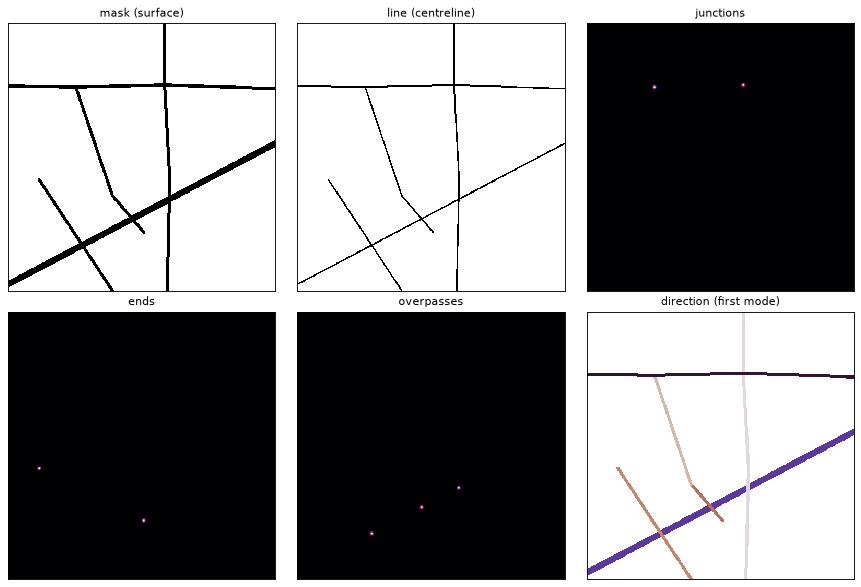

In [3]:
targets = road_targets(graph, SHAPE, crossings=crossings)
print({k: v.shape for k, v in targets.items()})
angle = 0.5 * np.arctan2(targets["direction"][1], targets["direction"][0])
panels = [("mask (surface)", targets["mask"], "gray_r"),
          ("line (centreline)", targets["line"], "gray_r"),
          ("junctions", targets["keypoints"][0], "magma"),
          ("ends", targets["keypoints"][1], "magma"),
          ("overpasses", targets["keypoints"][2], "magma"),
          ("direction (first mode)", np.ma.masked_where(targets["mask"] < 0.5, angle), "twilight")]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, (title, image, cmap) in zip(axes.flat, panels):
    ax.imshow(image, cmap=cmap, interpolation="nearest")
    ax.set(title=title, xticks=[], yticks=[])
fig.tight_layout()

## The model

`road_heads` is the preset. We build the model only to check its output shapes. The decoder reads
probabilities from the mask and keypoint heads and plain values from direction. It doesn't read the
line head.

In [4]:
LOGIT_HEADS = ("mask", "line", "keypoints")
model = create_model(backbone="resnet18", pretrained=False, in_channels=3,
                     heads=road_heads()).eval()
with torch.no_grad():
    out = model(torch.rand(1, 3, 256, 256))
print({head: tuple(v.shape) for head, v in out.items()})

# A trained model's stitched scene would go here:
# fields = {k: (v.sigmoid() if k in LOGIT_HEADS else v)[0].numpy() for k, v in out.items()
#           if k != "line"}
fields = {k: targets[k] for k in ("mask", "keypoints", "direction")}

{'mask': (1, 1, 256, 256), 'line': (1, 1, 256, 256), 'keypoints': (1, 3, 256, 256), 'direction': (1, 4, 256, 256)}


## Decode block by block

The decoder returns a `VectorGraph`. This scene uses 256 px blocks with a 64 px halo, and the result
should match decoding the whole scene in one go. The check that matters most is whether any
decoded junction landed on an overpass. If none did, the bridges survived.

same as decoding in one go: True
2 junctions, 3 of 3 overpasses kept, 2168 px of road (2169 in the input)


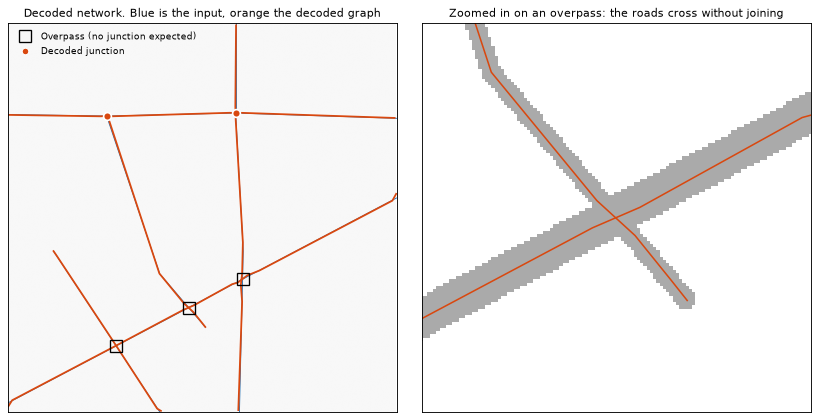

In [5]:
scene = Scene(*SHAPE, transform=TRANSFORM, crs=CRS)
decoder = block_decoder("roads")
decoded = decode_scene(fields, decoder, block=256, halo=64, scene=scene)
whole = decode_scene(fields, decoder, scene=scene)
same = np.array_equal(decoded.xy, whole.xy) and np.array_equal(decoded.edges, whole.edges)
print("same as decoding in one go:", same)


def summarise(g):
    junctions = g.junctions()
    if len(junctions):
        kept = sum(np.hypot(*(junctions - c).T).min() > 15 for c in crossings)
    else:
        kept = len(crossings)
    length = sum(shapely.LineString(p).length for p in g.polylines())
    return len(junctions), kept, length


true_length = sum(line.length for line in lines)
n_junctions, kept, length = summarise(decoded)
print(f"{n_junctions} junctions, {kept} of {len(crossings)} overpasses kept, "
      f"{length:.0f} px of road ({true_length:.0f} in the input)")


def draw_graph(ax, g, colour=ORANGE, lw=1.6, truth=True):
    ax.imshow(np.full(SHAPE, 0.97), cmap="gray", vmin=0, vmax=1)
    if truth:
        for line in lines:
            ax.plot(*np.asarray(line.coords).T, c=BLUE, lw=0.8)
    for polyline in g.polylines():
        ax.plot(*np.asarray(polyline).T, c=colour, lw=lw)
    junctions = g.junctions()
    if len(junctions):
        ax.plot(*junctions.T, "o", c=colour, ms=7, mec="white", mew=1.5)
    ax.set(xticks=[], yticks=[], xlim=(0, SHAPE[1]), ylim=(SHAPE[0], 0))


fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.2))
draw_graph(axes[0], decoded)
axes[0].plot(*np.asarray(crossings).T, "s", mfc="none", mec="black", ms=11, mew=1.2,
             label="Overpass (no junction expected)")
axes[0].plot([], [], "o", c=ORANGE, mec="white", label="Decoded junction")
axes[0].legend(frameon=False, loc="upper left", fontsize=8)
axes[0].set_title("Decoded network. Blue is the input, orange the decoded graph")
axes[1].imshow(fields["mask"], cmap="gray_r", vmin=0, vmax=3)
for polyline in decoded.polylines():
    axes[1].plot(*np.asarray(polyline).T, c=ORANGE, lw=1.4)
cx, cy = np.asarray(crossings)[1]
axes[1].set(xlim=(cx - 60, cx + 60), ylim=(cy + 60, cy - 60), xticks=[], yticks=[],
            title="Zoomed in on an overpass: the roads cross without joining")
fig.tight_layout()

## What does noise do?

We blur the mask and keypoint maps and add smooth noise. This is a rough stand-in for a real model's
output, so read the trend and not the scores. Road length holds up for longer than the structure
does. Noise above the decoder's keypoint threshold shows up as false junctions, including at the
overpasses, and a route-finding tool would then send traffic off a bridge.

RoadBlockDecoder({'threshold': 0.3, 'keypoint_threshold': 0.2, 'zone_radius': 8.0, 'pair_deg': 150.0, 'spur': 30, 'gap': 50, 'simplify': 2.0, 'min_length': 20, 'min_area': 30, 'logits': False}, names={'mask': 'mask', 'keypoints': 'keypoints', 'direction': 'direction'})
Clean mask: junctions 2, overpasses clear 3, 2168 px of road


Blur 1, noise 0.1: junctions 7, overpasses clear 0, 2204 px of road


Blur 1.5, noise 0.2: junctions 14, overpasses clear 0, 2711 px of road


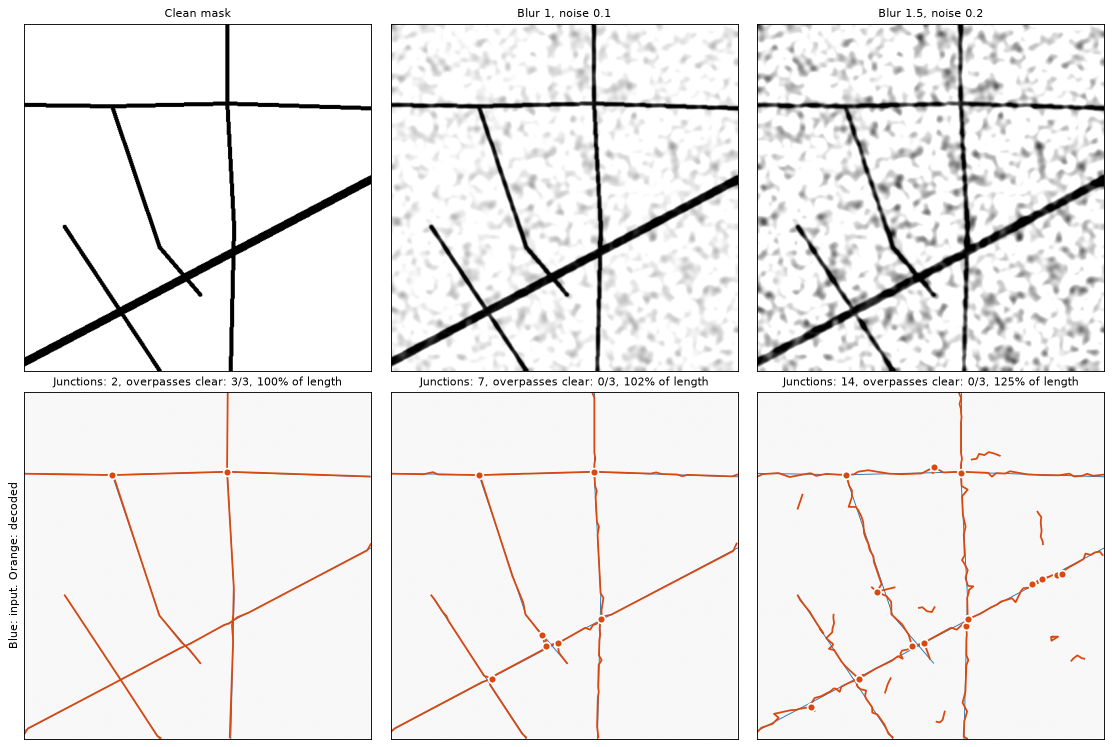

In [6]:
print(decoder)  # threshold is the road surface's; gap is how far apart loose ends may join


def damage(fields, blur=0.0, noise=0.0, patch=None, seed=0):
    rng = np.random.default_rng(seed)
    out = dict(fields)
    for head in ("mask", "keypoints"):
        array = fields[head].astype(np.float32)
        axes = (0,) * (array.ndim - 2)
        if blur:
            array = gaussian_filter(array, axes + (blur, blur))
        if noise:
            grain = gaussian_filter(rng.normal(size=array.shape).astype(np.float32), axes + (4, 4))
            array = array + noise * grain / grain.std()
        if patch:
            array = array.copy()
            array[..., patch[0]:patch[1], patch[2]:patch[3]] = 0
        out[head] = np.clip(array, 0, 1)
    return out


def compare(cases):
    fig, axes = plt.subplots(2, len(cases), figsize=(4.7 * len(cases), 9.4))
    for column, (title, kwargs) in zip(axes.T, cases):
        damaged = damage(fields, **kwargs)
        g = decode_scene(damaged, decoder, block=256, halo=64, scene=scene)
        n_junctions, kept, length = summarise(g)
        column[0].imshow(damaged["mask"], cmap="gray_r", vmin=0, vmax=1)
        column[0].set(title=title, xticks=[], yticks=[])
        draw_graph(column[1], g)
        column[1].set_title(f"Junctions: {n_junctions}, overpasses clear: {kept}/{len(crossings)}, "
                            f"{length / true_length:.0%} of length")
        print(f"{title}: junctions {n_junctions}, overpasses clear {kept}, {length:.0f} px of road")
    axes[1, 0].set_ylabel("Blue: input. Orange: decoded")
    fig.tight_layout()


compare([("Clean mask", {}), ("Blur 1, noise 0.1", {"blur": 1.0, "noise": 0.1}),
         ("Blur 1.5, noise 0.2", {"blur": 1.5, "noise": 0.2})])

## What does a gap do?

Trees and shadows hide stretches of road, so a model's mask breaks up. The decoder joins loose ends
that are close enough, so here we erase a stretch of the main street on either side of that limit.
The 40 px gap should close. The 80 px gap shouldn't, and that removes the left-hand junction too,
because only two arms still meet there. If joining ends is wrong for your data, `gap=0` turns it off.

40 px gap: junctions 2, overpasses clear 3, 2168 px of road
80 px gap: junctions 1, overpasses clear 3, 2056 px of road


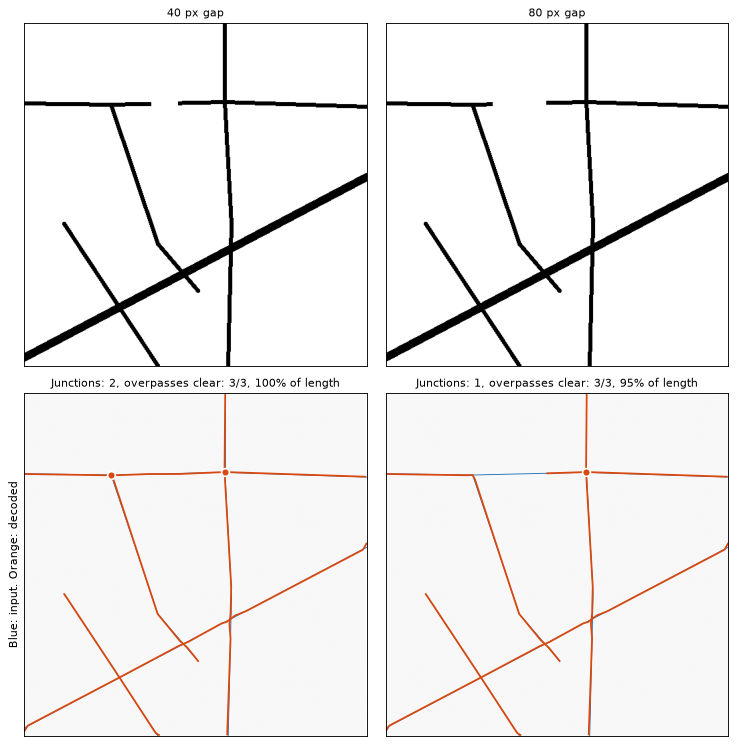

In [7]:
compare([("40 px gap", {"patch": (100, 145, 190, 230)}),
         ("80 px gap", {"patch": (100, 145, 160, 240)})])

## Write GeoJSON

`write_records` turns the graph into one LineString per chain between junctions and ends, in metres.

In [8]:
with TemporaryDirectory() as tmp:
    path = write_records(decoded, Path(tmp) / "roads.geojson", scene)
    collection = json.loads(Path(path).read_text())
metres = sum(shapely.geometry.shape(f["geometry"]).length for f in collection["features"])
print(f"{len(collection['features'])} lines, {metres:.0f} m of road")

8 lines, 2168 m of road


## Where to go next

* The training losses are in
  [`examples/vector_presets.py`](https://github.com/DPIRD-DMA/ManySeg/blob/main/examples/vector_presets.py).
* See the other vector outputs: [footprints](03_vector_footprints.ipynb),
  [fields](04_vector_fields.ipynb), [roofs](06_vector_roofs.ipynb) and
  [points](07_vector_points.ipynb).